# DATA 250 PROJECT 4
Student: Minh Pham

# 1. Introduction

In this project, I aim to predict whether the home team will win a soccer match based on information available before the match. Predicting match outcomes is an important problem in sports analytics and is widely used in areas such as betting markets and team strategy.

The dataset used in this project comes from the European Soccer Database on Kaggle. It contains information about thousands of matches across multiple European leagues and seasons. For this analysis, I will focus on match-level data and create a binary response variable indicating whether the home team won the match.

**Research Question: Can we predict whether the home team will win a soccer match based on match statistics?**

I use the following features in the analysis:

- `avg_home_odds`, `avg_draw_odds`, `avg_away_odds`: Average betting odds from multiple bookmakers, representing the predicted likelihood of each outcome
- `stage`: The match week within the season
- `month`: The month in which the match was played
- `day_of_week`: The day of the week of the match
- `league_id`: Identifier for the league
- `season`: The season in which the match took place

My goal is to determine how well these features can predict match outcomes and to compare different classification models based on their performance.

First, import all necessary packages, and prepare our dataset.

In [ ]:
import sqlite3
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
import statsmodels.api as sm

In [38]:

# connect to database (local to my computer,
# somehow the import dataset code from Kaggle returns a bad request)
conn = sqlite3.connect(r"E:\data250_2026sp\Project 4\hugomathien\soccer\versions\10\database.sqlite")

# load Match table
df = pd.read_sql("SELECT * FROM Match;", conn)


df.head()
df.columns

Index(['id', 'country_id', 'league_id', 'season', 'stage', 'date',
       'match_api_id', 'home_team_api_id', 'away_team_api_id',
       'home_team_goal',
       ...
       'SJA', 'VCH', 'VCD', 'VCA', 'GBH', 'GBD', 'GBA', 'BSH', 'BSD', 'BSA'],
      dtype='object', length=115)

In [ ]:
# Response Variable
df["HomeWin"] = (df["home_team_goal"] > 
                 df["away_team_goal"]).astype(int)

In [40]:
# Find the average odds of 3 betting sites
df["avg_home_odds"] = df[["B365H", "BWH", "IWH"]].mean(axis=1)
df["avg_draw_odds"] = df[["B365D", "BWD", "IWD"]].mean(axis=1)
df["avg_away_odds"] = df[["B365A", "BWA", "IWA"]].mean(axis=1)

In [41]:
# Date and time 
df["month"] = pd.to_datetime(df["date"]).dt.month
df["day_of_week"] = pd.to_datetime(df["date"]).dt.dayofweek

In [42]:
# Feature set
features = [
    "avg_home_odds",
    "avg_draw_odds",
    "avg_away_odds",
    "stage",
    "month",
    "day_of_week",
    "league_id",
    "season"
]

In [43]:
df = df[features + ["HomeWin"]].dropna()
df

,avg_home_odds,avg_draw_odds,avg_away_odds,stage,month,day_of_week,league_id,season,HomeWin
0,1.776667,3.316667,4.233333,1,8,6,1,2008/2009,0
1,1.883333,3.233333,3.683333,1,8,5,1,2008/2009,0
2,2.460000,3.233333,2.533333,1,8,5,1,2008/2009,0
3,1.413333,3.883333,6.766667,1,8,6,1,2008/2009,1
4,4.666667,3.433333,1.650000,1,8,5,1,2008/2009,0
...,...,...,...,...,...,...,...,...,...
24552,1.596667,3.833333,5.966667,9,10,6,21518,2015/2016,1
24553,2.266667,3.183333,3.233333,9,10,5,21518,2015/2016,1
24554,1.560000,3.900000,6.300000,9,10,0,21518,2015/2016,1
24555,2.350000,3.266667,3.000000,9,10,5,21518,2015/2016,0


# 2. Exploratory Data Analysis

## A. Missing Values
We begin by checking for missing values in the dataset. Missing data can impact model performance and may introduce bias if not handled properly.

In [44]:
df.isnull().sum()

avg_home_odds    0
avg_draw_odds    0
avg_away_odds    0
stage            0
month            0
day_of_week      0
league_id        0
season           0
HomeWin          0
dtype: int64

The dataset is now very clean with 0 N/A values for all feature columns. We still have over 22,000 values.

## B. Response Variable Distribution

Next, we examine the distribution of our response variable, `HomeWin`, to check for class imbalance.

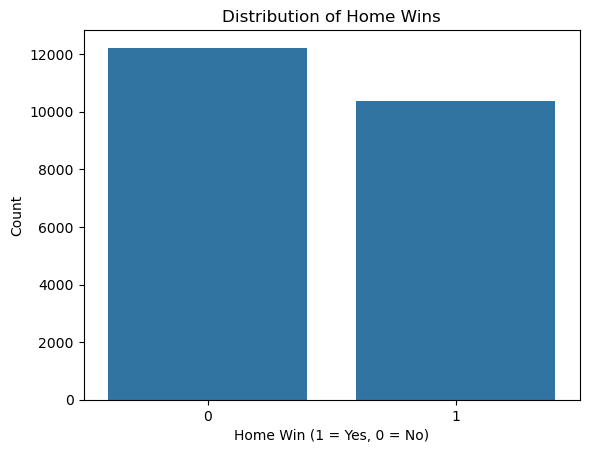

In [45]:
sns.countplot(x="HomeWin", data=df)
plt.title("Distribution of Home Wins")
plt.xlabel("Home Win (1 = Yes, 0 = No)")
plt.ylabel("Count")
plt.show()

The dataset shows that home wins occur more frequently than non-wins. This indicates a moderate class imbalance, which may affect model performance. For example, a model that always predicts a home win could achieve relatively high accuracy, so we should interpret accuracy carefully.

## C. Bivariate Relationships

We now examine the relationship between each feature and the response variable to identify which features are most predictive.

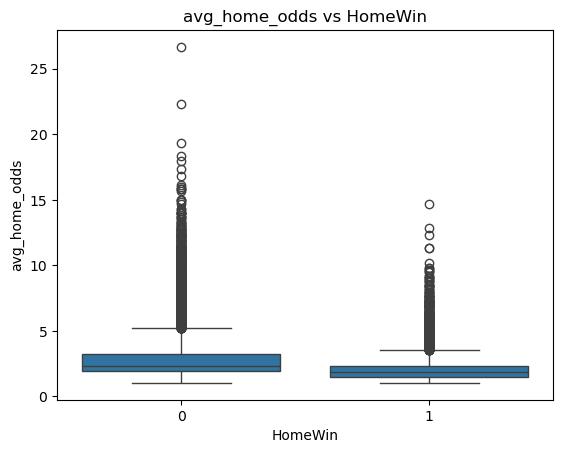

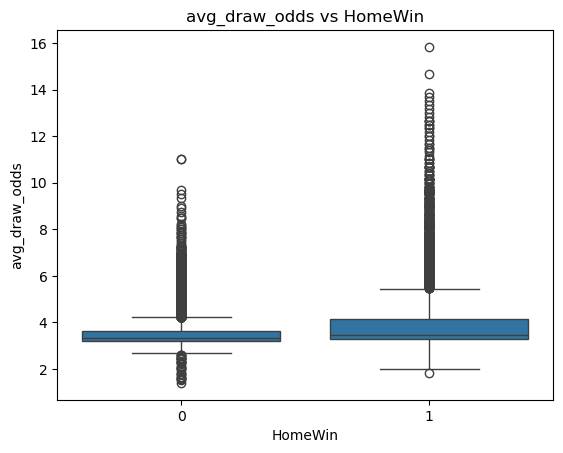

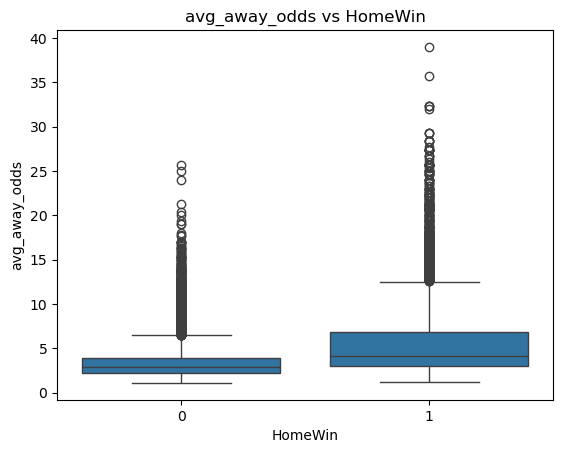

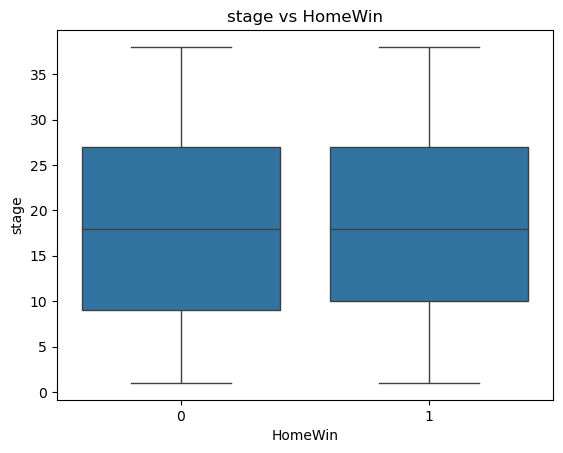

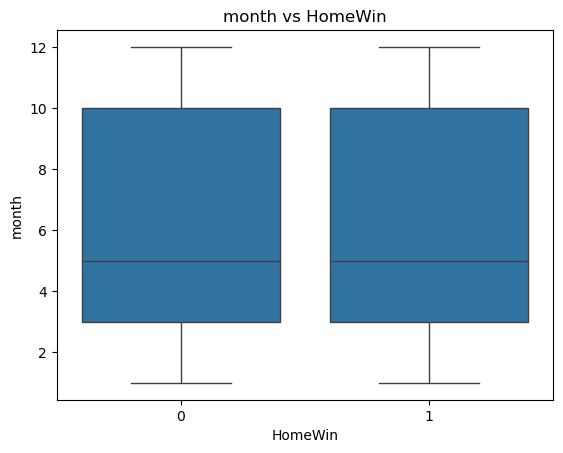

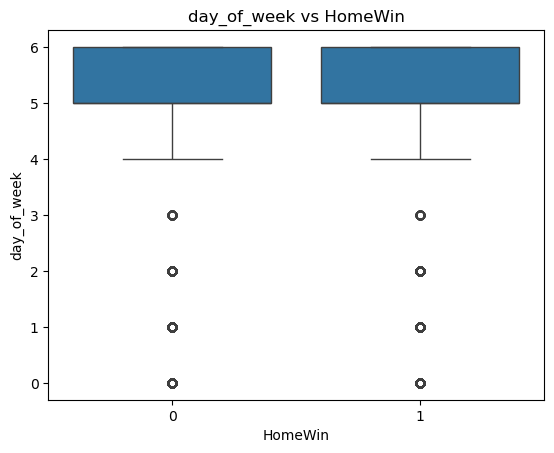

In [ ]:
# Quantitative Features
quant_cols = ["avg_home_odds", 
              "avg_draw_odds", 
              "avg_away_odds", 
              "stage", 
              "month", 
              "day_of_week"]

for col in quant_cols:
    sns.boxplot(x="HomeWin", y=col, data=df)
    plt.title(f"{col} vs HomeWin")
    plt.show()

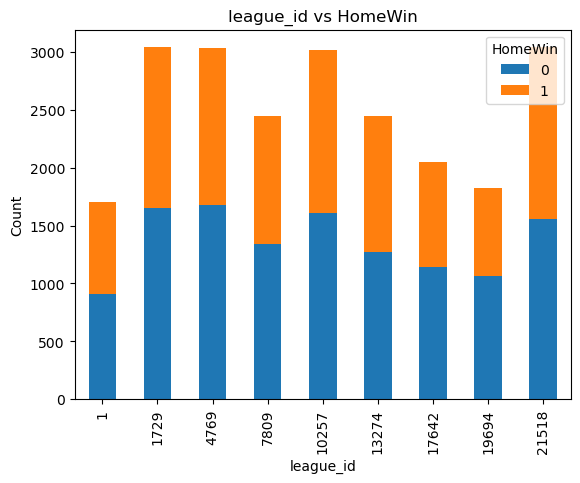

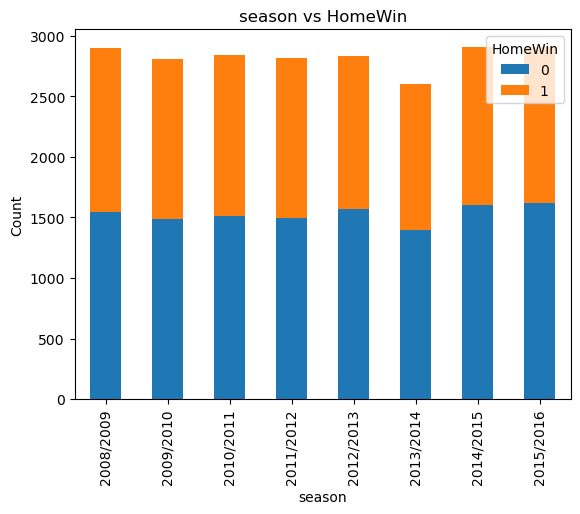

In [ ]:
# Categorical Features
cat_cols = ["league_id", "season"]

for col in cat_cols:
    pd.crosstab(df[col], df["HomeWin"]).plot(
        kind="bar", stacked=True)
    plt.title(f"{col} vs HomeWin")
    plt.ylabel("Count")
    plt.show()

The betting odds features show the strongest relationship with match outcomes. In particular, lower values of `avg_home_odds` are associated with a higher likelihood of a home win, which aligns with the interpretation of betting odds as probabilities.

The draw and away odds also show clear separation between classes, though less pronounced. Temporal features such as `month` and `day_of_week` show weaker relationships, suggesting that match timing has less influence on outcomes.

Categorical variables such as league and season show some variation, indicating that certain leagues or seasons may have different competitive dynamics.

## D. Pairplot (Collinearity Check)

We use a pairplot to visualize relationships between key quantitative variables and check for potential collinearity.

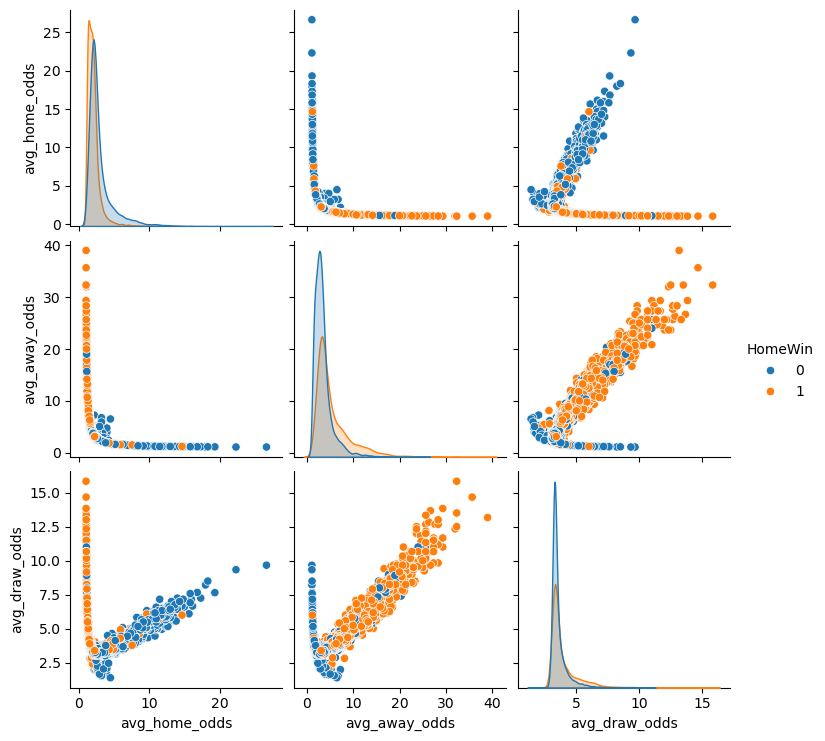

In [ ]:
sns.pairplot(df[["avg_home_odds", 
                 "avg_away_odds", 
                 "avg_draw_odds", 
                 "HomeWin"]],
             hue="HomeWin")
plt.show()

The pairplot shows that the betting odds variables are somewhat correlated with each other, which is expected since they all represent probabilities of match outcomes. This suggests potential multicollinearity, which may affect logistic regression models. However, the relationships are not perfectly linear, so the variables still provide useful predictive information.

## E. Model Expectation

Based on the exploratory analysis, we consider which classification model may perform best.

The betting odds features show strong predictive power and relatively clear separation between classes, suggesting that all three models (KNN, logistic regression, and random forests) should perform reasonably well.

However, due to potential non-linear relationships and interactions between features, a random forest classifier may perform best after tuning. Logistic regression is expected to provide interpretable results, while KNN may perform moderately depending on feature scaling and distance structure.

# 3. Proof of Concept Model Fitting

## A. Scatterplot of 2 features

Based on the exploratory data analysis, we selected two quantitative features that appear most predictive of the response: `avg_home_odds` and `avg_away_odds`. We visualize their relationship with the response variable to assess whether there is any separation between classes.

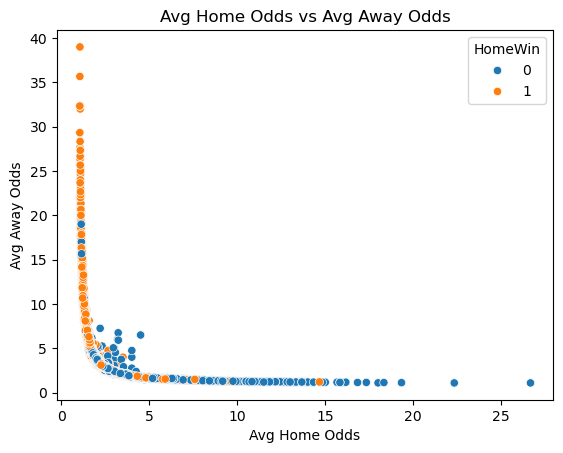

In [49]:
sns.scatterplot(x="avg_home_odds",
                y="avg_away_odds",
                hue="HomeWin",
                data=df)

plt.title("Avg Home Odds vs Avg Away Odds")
plt.xlabel("Avg Home Odds")
plt.ylabel("Avg Away Odds")
plt.show()

The scatterplot shows some separation between the two classes. Matches with lower home odds and higher away odds tend to result in home wins, which somewhat aligns with expectations. However, there is still significant overlap between the classes, indicating that perfect classification is not possible with these two features alone.

## B. KNN Classifier (k = 3)

We fit a KNN model with `k = 3` using the 2 selected features. 

In [50]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Select features
X_small = df[["avg_home_odds", "avg_away_odds"]]
y = df["HomeWin"]

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_small)

# Fit KNN
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_scaled, y)

# Predictions
y_pred_knn = knn.predict(X_scaled)

# Accuracy
print("KNN Accuracy:", accuracy_score(y, y_pred_knn))

KNN Accuracy: 0.7648698884758365


The KNN classifier achieves moderate accuracy of `76%` using only these two features. This suggests that local patterns in the feature space provide useful information for predicting match outcomes. However, the model is limited by the overlap observed in the scatterplot.

## C. Logistic Regression

Next, we fit a logistic regression model using the same two features. Logistic regression does not require scaling in this context, so we use the unscaled data.

In [55]:
log_reg = LogisticRegression(penalty=None)
log_reg.fit(X_small, y)

y_pred_log = log_reg.predict(X_small)

print("Logistic Regression Accuracy:", accuracy_score(y, y_pred_log))

# Add constant
X_sm = sm.add_constant(X_small)

model = sm.Logit(y, X_sm)
result = model.fit()

print(result.summary())

Logistic Regression Accuracy: 0.6516640113294389
Optimization terminated successfully.
         Current function value: 0.616519
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:                HomeWin   No. Observations:                22596
Model:                          Logit   Df Residuals:                    22593
Method:                           MLE   Df Model:                            2
Date:                Wed, 08 Apr 2026   Pseudo R-squ.:                  0.1062
Time:                        15:42:53   Log-Likelihood:                -13931.
converged:                       True   LL-Null:                       -15587.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
const            -0.1528      0.066     -2.308      0

The logistic regression model provides similar accuracy to KNN, indicating that these features contain meaningful predictive information. The coefficients show that lower home odds increase the probability of a home win, while higher away odds also increase this probability. The statistical significance of these coefficients suggests that both features are important predictors.